Load the 2-year preprocessed sales data from notebook 02 and train a Random Forest and Decision Tree regressor.

In [37]:
from pathlib import Path
import os
import numpy as np
import pandas as pd

DATA_DIR = Path(os.getenv("IDX_DATA_DIR", "data"))
df = pd.read_csv(DATA_DIR / "processed/sales_preprocessed_2.csv")

train = df[df["split"] == "train"].drop(columns=["split"])
test = df[df["split"] == "test"].drop(columns=["split"])

y_train = train["ClosePrice"]
X_train = train.drop(columns=["ClosePrice"])
y_test = test["ClosePrice"]
X_test = test.drop(columns=["ClosePrice"])

y_train_log = np.log(y_train)
y_test_log = np.log(y_test)

print(X_train.shape, X_test.shape)

(241678, 601) (9849, 601)


In [38]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tree = DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=0)
tree.fit(X_train, y_train_log)

y_pred_tree_log = tree.predict(X_test)
y_pred_tree = np.exp(y_pred_tree_log)

print("decision tree ")
print("test RMSE (dollars):", np.sqrt(mean_squared_error(y_test, y_pred_tree)))
print("test R^2 (dollars):", r2_score(y_test, y_pred_tree))

decision tree 
test RMSE (dollars): 396929.84331410914
test R^2 (dollars): 0.7766261721734594


In [39]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

rf = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=20,
    n_jobs=-1,
    random_state=0,
)
rf.fit(X_train, y_train_log)

y_pred_log = rf.predict(X_test)
y_pred = np.exp(y_pred_log)

print("random forest (log price target)")
print("train R^2 (log):", rf.score(X_train, y_train_log))
print("test R^2 (log):", r2_score(y_test_log, y_pred_log))
print("test RMSE (dollars):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("test R^2 (dollars):", r2_score(y_test, y_pred))

random forest (log price target)
train R^2 (log): 0.9355834271897705
test R^2 (log): 0.9173855110423419
test RMSE (dollars): 305685.8191301643
test R^2 (dollars): 0.8675184607622761


Redo both models on the 2-year target-encoded data from notebook 02_copy (City, PostalCode, HighSchoolDistrict means).

In [40]:
df_te = pd.read_csv(DATA_DIR / "processed/sales_preprocessed_1_target_encoded.csv")

train_te = df_te[df_te["split"] == "train"].drop(columns=["split"])
test_te = df_te[df_te["split"] == "test"].drop(columns=["split"])

y_train_te = train_te["ClosePrice"]
X_train_te = train_te.drop(columns=["ClosePrice"])
y_test_te = test_te["ClosePrice"]
X_test_te = test_te.drop(columns=["ClosePrice"])

y_train_te_log = np.log(y_train_te)
y_test_te_log = np.log(y_test_te)

print(X_train_te.shape, X_test_te.shape)

(120373, 114) (9827, 114)


In [41]:
tree_te = DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=0)
tree_te.fit(X_train_te, y_train_te_log)

y_pred_tree_te = np.exp(tree_te.predict(X_test_te))

print("decision tree (target encoded)")
print("test RMSE (dollars):", np.sqrt(mean_squared_error(y_test_te, y_pred_tree_te)))
print("test R^2 (dollars):", r2_score(y_test_te, y_pred_tree_te))

decision tree (target encoded)
test RMSE (dollars): 335217.9692525492
test R^2 (dollars): 0.8401232446166378


In [42]:
rf_te = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=20,
    n_jobs=-1,
    random_state=0,
)
rf_te.fit(X_train_te, y_train_te_log)

y_pred_te_log = rf_te.predict(X_test_te)
y_pred_te = np.exp(y_pred_te_log)

print("random forest (target encoded)")
print("train R^2 (log):", rf_te.score(X_train_te, y_train_te_log))
print("test R^2 (log):", r2_score(y_test_te_log, y_pred_te_log))
print("test RMSE (dollars):", np.sqrt(mean_squared_error(y_test_te, y_pred_te)))
print("test R^2 (dollars):", r2_score(y_test_te, y_pred_te))

random forest (target encoded)
train R^2 (log): 0.9385738039981179
test R^2 (log): 0.904482460004153
test RMSE (dollars): 305558.37465011224
test R^2 (dollars): 0.8671629792462922


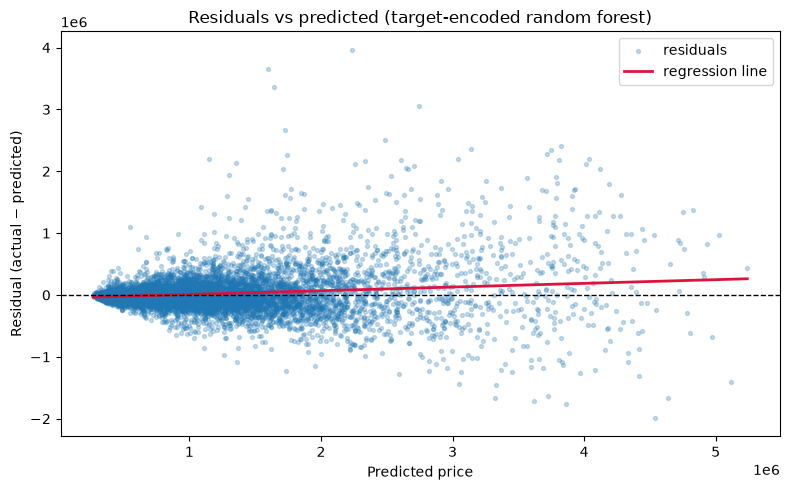

In [43]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

residuals = y_test_te - y_pred_te
resid_line = LinearRegression().fit(y_pred_te.reshape(-1, 1), residuals)
x_line = np.linspace(y_pred_te.min(), y_pred_te.max(), 200)
y_line = resid_line.predict(x_line.reshape(-1, 1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_pred_te, residuals, alpha=0.25, s=8, label="residuals")
ax.plot(x_line, y_line, color="crimson", linewidth=2, label="regression line")
ax.axhline(0, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Predicted price")
ax.set_ylabel("Residual (actual − predicted)")
ax.set_title("Residuals vs predicted (target-encoded random forest)")
ax.legend()
plt.tight_layout()
plt.show()

Two-stage random forest on the target-encoded data: classify high-end vs typical from features, then route to a low-price or high-price forest.

In [44]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

HIGH_CUTOFF = 2_000_000
rf_params = dict(n_estimators=100, max_depth=20, min_samples_leaf=20, n_jobs=-1, random_state=0)

y_high_train = (y_train_te > HIGH_CUTOFF).astype(int)

clf = RandomForestClassifier(**rf_params, class_weight="balanced")
clf.fit(X_train_te, y_high_train)

low_mask = y_train_te <= HIGH_CUTOFF
high_mask = y_train_te > HIGH_CUTOFF
rf_low = RandomForestRegressor(**rf_params)
rf_high = RandomForestRegressor(**rf_params)
rf_low.fit(X_train_te[low_mask], y_train_te_log[low_mask])
rf_high.fit(X_train_te[high_mask], y_train_te_log[high_mask])

y_high_pred = clf.predict(X_test_te)
y_pred_split_log = np.where(
    y_high_pred == 1,
    rf_high.predict(X_test_te),
    rf_low.predict(X_test_te),
)
y_pred_split = np.exp(y_pred_split_log)

low_test = y_test_te <= HIGH_CUTOFF
high_test = y_test_te > HIGH_CUTOFF

print("low houses")
print("test RMSE:", np.sqrt(mean_squared_error(y_test_te[low_test], y_pred_split[low_test])))
print("test R^2:", r2_score(y_test_te[low_test], y_pred_split[low_test]))
print("high houses")
print("test RMSE:", np.sqrt(mean_squared_error(y_test_te[high_test], y_pred_split[high_test])))
print("test R^2:", r2_score(y_test_te[high_test], y_pred_split[high_test]))

low houses
test RMSE: 272360.78868943825
test R^2: 0.5636402143923447
high houses
test RMSE: 664834.7576528682
test R^2: 0.4691144687955192


Grid-search the split model's two random forest regressors on train only (3-fold CV, log-price R²). The classifier is unchanged. This cell can take a while.

In [45]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

HIGH_CUTOFF = 2_000_000
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [12, 20],
    "min_samples_leaf": [10, 20],
}

y_high_train = (y_train_te > HIGH_CUTOFF).astype(int)
low_mask = y_train_te <= HIGH_CUTOFF
high_mask = y_train_te > HIGH_CUTOFF

clf = RandomForestClassifier(
    n_estimators=100, max_depth=20, min_samples_leaf=20,
    class_weight="balanced", n_jobs=-1, random_state=0,
)
clf.fit(X_train_te, y_high_train)

rf_base = RandomForestRegressor(n_jobs=-1, random_state=0)
grid_low = GridSearchCV(rf_base, param_grid, cv=3, scoring="r2", n_jobs=1, verbose=1)
grid_high = GridSearchCV(rf_base, param_grid, cv=3, scoring="r2", n_jobs=1, verbose=1)

grid_low.fit(X_train_te[low_mask], y_train_te_log[low_mask])
grid_high.fit(X_train_te[high_mask], y_train_te_log[high_mask])
print("best low params:", grid_low.best_params_, "cv R^2:", grid_low.best_score_)
print("best high params:", grid_high.best_params_, "cv R^2:", grid_high.best_score_)

y_high_pred = clf.predict(X_test_te)
y_pred_split = np.exp(np.where(
    y_high_pred == 1,
    grid_high.best_estimator_.predict(X_test_te),
    grid_low.best_estimator_.predict(X_test_te),
))

low_test = y_test_te <= HIGH_CUTOFF
high_test = y_test_te > HIGH_CUTOFF
print("low houses")
print("test RMSE:", np.sqrt(mean_squared_error(y_test_te[low_test], y_pred_split[low_test])))
print("test R^2:", r2_score(y_test_te[low_test], y_pred_split[low_test]))
print("high houses")
print("test RMSE:", np.sqrt(mean_squared_error(y_test_te[high_test], y_pred_split[high_test])))
print("test R^2:", r2_score(y_test_te[high_test], y_pred_split[high_test]))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Fitting 3 folds for each of 8 candidates, totalling 24 fits
best low params: {'max_depth': 20, 'min_samples_leaf': 10, 'n_estimators': 100} cv R^2: 0.9006482432028453
best high params: {'max_depth': 20, 'min_samples_leaf': 10, 'n_estimators': 100} cv R^2: 0.6046776322541322
low houses
test RMSE: 268150.7249235348
test R^2: 0.5770261637196992
high houses
test RMSE: 648231.427489171
test R^2: 0.49529963156664436


In [46]:
old_feature_set_RMSE_high: 648231.4274891712
old_feature_set_RMSE_low: 268150.72492353484
old_feature_set_MAE_high: 457648.1942285055
old_feature_set_MAE_low: 150688.19696191177

Feature engineering on the target-encoded data: bed/bath ratio and property age in years.

In [ ]:
REFERENCE_YEAR = 2025

baths = df_te["BathroomsTotalInteger"].replace(0, np.nan)
df_te["BedBathRatio"] = df_te["BedroomsTotal"] / baths
df_te["BedBathRatio"] = df_te["BedBathRatio"].fillna(df_te["BedBathRatio"].median())

year_built = df_te["YearBuilt"].where(df_te["YearBuilt_missing"] == 0)
df_te["PropertyAge"] = (REFERENCE_YEAR - year_built).clip(lower=0)
df_te["PropertyAge"] = df_te["PropertyAge"].fillna(df_te["PropertyAge"].median())

df_te[["BedroomsTotal", "BathroomsTotalInteger", "BedBathRatio", "YearBuilt", "PropertyAge"]].describe()

/var/folders/1t/kf306rwj34dfb9gwk0v_nqvr0000gn/T/ipykernel_18684/430555938.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_te["BedBathRatio"] = df_te["BedroomsTotal"] / baths
/var/folders/1t/kf306rwj34dfb9gwk0v_nqvr0000gn/T/ipykernel_18684/430555938.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_te["PropertyAge"] = (REFERENCE_YEAR - year_built).clip(lower=0)


,BedroomsTotal,BathroomsTotalInteger,BedBathRatio,YearBuilt,PropertyAge
count,130200.000000,130200.000000,130200.000000,130200.000000,130200.000000
mean,3.473495,2.552519,1.474599,1974.947581,49.187788
std,0.855942,0.931798,0.463128,49.069626,26.448275
min,2.000000,0.000000,0.333333,0.000000,0.000000
25%,3.000000,2.000000,1.000000,1956.000000,28.000000
50%,3.000000,2.000000,1.500000,1975.000000,50.000000
75%,4.000000,3.000000,1.500000,1997.000000,69.000000
max,6.000000,6.000000,5.000000,2025.000000,115.000000


Map each listing's coordinates to its 2024-25 California school districts and target-encode them like notebook 02_copy (train-only means, smoothing 20). 

In [ ]:
import geopandas as gpd

# the .shx index wasn't exported with the .shp; let GDAL rebuild it
os.environ["SHAPE_RESTORE_SHX"] = "YES"

districts = pd.read_csv(DATA_DIR / "raw/csv/California_School_District_Areas_2024-25.csv", usecols=["CDCode", "DistrictName", "DistrictType"])
shapes = gpd.read_file(DATA_DIR / "raw/csv/DistrictAreas2425.shp")
assert len(shapes) == len(districts)
districts = gpd.GeoDataFrame(districts, geometry=shapes.geometry.make_valid().values, crs="EPSG:3857")

points = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(df_te["Longitude"], df_te["Latitude"]),
    index=df_te.index,
    crs="EPSG:4326",
).to_crs(districts.crs)

district_levels = {
    "SecondaryDistrict": ["High", "Unified"],
    "ElementaryDistrict": ["Elementary", "Unified"],
}

train_mask = df_te["split"] == "train"
global_mean = df_te.loc[train_mask, "ClosePrice"].mean()
smooth_k = 20

district_keys = {}
for col, types in district_levels.items():
    matches = gpd.sjoin(points, districts[districts["DistrictType"].isin(types)], how="left", predicate="within")
    matches["type_rank"] = matches["DistrictType"].map({t: i for i, t in enumerate(types)})
    matches = matches.sort_values("type_rank", kind="stable")
    matches = matches[~matches.index.duplicated(keep="first")].sort_index()
    district_keys[col] = matches["CDCode"]

    keys = matches["CDCode"].astype("string").fillna("__missing__")
    df_te[f"{col}_missing"] = matches["CDCode"].isna().astype("int8")
    stats = df_te.loc[train_mask].groupby(keys[train_mask])["ClosePrice"].agg(["mean", "count"])
    encoded_mean = (stats["count"] * stats["mean"] + smooth_k * global_mean) / (stats["count"] + smooth_k)
    df_te[f"{col}_te"] = keys.map(encoded_mean).fillna(global_mean)
    print(col, "unmatched:", df_te[f"{col}_missing"].sum(), "districts:", matches["CDCode"].nunique())

df_te[["SecondaryDistrict_te", "ElementaryDistrict_te"]].describe()

/var/folders/1t/kf306rwj34dfb9gwk0v_nqvr0000gn/T/ipykernel_18684/2403472697.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_te[f"{col}_missing"] = matches["CDCode"].isna().astype("int8")
/var/folders/1t/kf306rwj34dfb9gwk0v_nqvr0000gn/T/ipykernel_18684/2403472697.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_te[f"{col}_te"] = keys.map(encoded_mean).fillna(global_mean)


SecondaryDistrict unmatched: 112 districts: 373
ElementaryDistrict unmatched: 36 districts: 622


/var/folders/1t/kf306rwj34dfb9gwk0v_nqvr0000gn/T/ipykernel_18684/2403472697.py:37: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_te[f"{col}_missing"] = matches["CDCode"].isna().astype("int8")
/var/folders/1t/kf306rwj34dfb9gwk0v_nqvr0000gn/T/ipykernel_18684/2403472697.py:40: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_te[f"{col}_te"] = keys.map(encoded_mean).fillna(global_mean)


,SecondaryDistrict_te,ElementaryDistrict_te
count,1.302000e+05,1.302000e+05
mean,1.159017e+06,1.158235e+06
std,5.639292e+05,5.560231e+05
min,4.134300e+05,4.134300e+05
25%,7.514055e+05,7.514055e+05
50%,1.011950e+06,1.012489e+06
75%,1.449883e+06,1.449883e+06
max,3.634543e+06,4.088083e+06


Rerun the grid-searched split model on the new feature set (bed/bath ratio, property age, school district encodings) to compare against the old feature set numbers above. 

In [49]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

train_fe = df_te[df_te["split"] == "train"].drop(columns=["split"])
test_fe = df_te[df_te["split"] == "test"].drop(columns=["split"])

y_train_fe = train_fe["ClosePrice"]
X_train_fe = train_fe.drop(columns=["ClosePrice"])
y_test_fe = test_fe["ClosePrice"]
X_test_fe = test_fe.drop(columns=["ClosePrice"])
y_train_fe_log = np.log(y_train_fe)
print(X_train_fe.shape, X_test_fe.shape)

HIGH_CUTOFF = 2_000_000
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [12, 20],
    "min_samples_leaf": [10, 20],
}

y_high_train = (y_train_fe > HIGH_CUTOFF).astype(int)
low_mask = y_train_fe <= HIGH_CUTOFF
high_mask = y_train_fe > HIGH_CUTOFF

clf_fe = RandomForestClassifier(
    n_estimators=100, max_depth=20, min_samples_leaf=20,
    class_weight="balanced", n_jobs=-1, random_state=0,
)
clf_fe.fit(X_train_fe, y_high_train)

rf_base = RandomForestRegressor(n_jobs=-1, random_state=0)
grid_low_fe = GridSearchCV(rf_base, param_grid, cv=3, scoring="r2", n_jobs=1, verbose=1)
grid_high_fe = GridSearchCV(rf_base, param_grid, cv=3, scoring="r2", n_jobs=1, verbose=1)

grid_low_fe.fit(X_train_fe[low_mask], y_train_fe_log[low_mask])
grid_high_fe.fit(X_train_fe[high_mask], y_train_fe_log[high_mask])
print("best low params:", grid_low_fe.best_params_, "cv R^2:", grid_low_fe.best_score_)
print("best high params:", grid_high_fe.best_params_, "cv R^2:", grid_high_fe.best_score_)

y_high_pred = clf_fe.predict(X_test_fe)
y_pred_split_fe = np.exp(np.where(
    y_high_pred == 1,
    grid_high_fe.best_estimator_.predict(X_test_fe),
    grid_low_fe.best_estimator_.predict(X_test_fe),
))

low_test = y_test_fe <= HIGH_CUTOFF
high_test = y_test_fe > HIGH_CUTOFF
print("low houses")
print("test RMSE:", np.sqrt(mean_squared_error(y_test_fe[low_test], y_pred_split_fe[low_test])))
print("test MAE:", mean_absolute_error(y_test_fe[low_test], y_pred_split_fe[low_test]))
print("test R^2:", r2_score(y_test_fe[low_test], y_pred_split_fe[low_test]))
print("high houses")
print("test RMSE:", np.sqrt(mean_squared_error(y_test_fe[high_test], y_pred_split_fe[high_test])))
print("test MAE:", mean_absolute_error(y_test_fe[high_test], y_pred_split_fe[high_test]))
print("test R^2:", r2_score(y_test_fe[high_test], y_pred_split_fe[high_test]))

(120373, 120) (9827, 120)
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Fitting 3 folds for each of 8 candidates, totalling 24 fits
best low params: {'max_depth': 20, 'min_samples_leaf': 10, 'n_estimators': 100} cv R^2: 0.9024832584774974
best high params: {'max_depth': 20, 'min_samples_leaf': 10, 'n_estimators': 100} cv R^2: 0.6080470786734506
low houses
test RMSE: 266383.7374507255
test MAE: 148989.8767519099
test R^2: 0.5825821956660087
high houses
test RMSE: 645405.2044634499
test MAE: 457125.89898865146
test R^2: 0.4996909223056095


In [ ]:
comparison = {}
for name, y_true, y_hat in [
    ("old features", y_test_te, y_pred_split),
    ("new features", y_test_fe, y_pred_split_fe),
]:
    low = y_true <= HIGH_CUTOFF
    high = y_true > HIGH_CUTOFF
    comparison[name] = {
        "RMSE low": np.sqrt(mean_squared_error(y_true[low], y_hat[low])),
        "RMSE high": np.sqrt(mean_squared_error(y_true[high], y_hat[high])),
        "MAE low": mean_absolute_error(y_true[low], y_hat[low]),
        "MAE high": mean_absolute_error(y_true[high], y_hat[high]),
    }

comparison = pd.DataFrame(comparison).T
comparison.loc["change"] = comparison.loc["new features"] - comparison.loc["old features"]
comparison.round(0)

,RMSE low,RMSE high,MAE low,MAE high
old features,268151.0,648231.0,150688.0,457648.0
new features,266384.0,645405.0,148990.0,457126.0
change,-1767.0,-2826.0,-1698.0,-522.0


Out-of-fold target encoding: each train row's encoding comes from the other 4 folds, so it never includes its own price; test rows use all of train. Also adds price-per-sqft encodings for the same categories. 

In [ ]:
from sklearn.model_selection import KFold

df_v2 = df_te.copy()
is_train = (df_v2["split"] == "train").values
smooth_k = 20


def oof_target_encode(keys, target, n_splits=5):
    keys = keys.astype("string").fillna("__missing__")
    out = pd.Series(np.nan, index=keys.index)
    train_rows = np.where(is_train)[0]
    test_rows = np.where(~is_train)[0]

    def fit_apply(fit_rows, apply_rows):
        y = target.iloc[fit_rows]
        prior = y.mean()
        stats = y.groupby(keys.iloc[fit_rows]).agg(["mean", "count"])
        encoded_mean = (stats["count"] * stats["mean"] + smooth_k * prior) / (stats["count"] + smooth_k)
        return keys.iloc[apply_rows].map(encoded_mean).fillna(prior).values

    for fit, held in KFold(n_splits, shuffle=True, random_state=0).split(train_rows):
        out.iloc[train_rows[held]] = fit_apply(train_rows[fit], train_rows[held])
    out.iloc[test_rows] = fit_apply(train_rows, test_rows)
    return out


price = df_v2["ClosePrice"]
price_per_sqft = (price / df_v2["LivingArea"]).where(df_v2["LivingArea"] > 0)

category_keys = {col: df_te[f"{col}_te"] for col in ["City", "PostalCode", "HighSchoolDistrict"]}
category_keys.update(district_keys)

for col, keys in category_keys.items():
    df_v2[f"{col}_te"] = oof_target_encode(keys, price)
    df_v2[f"{col}_ppsf_te"] = oof_target_encode(keys, price_per_sqft)

df_v2[[f"{col}_ppsf_te" for col in category_keys]].describe()

,City_ppsf_te,PostalCode_ppsf_te,HighSchoolDistrict_ppsf_te,SecondaryDistrict_ppsf_te,ElementaryDistrict_ppsf_te
count,130200.000000,130200.000000,130200.000000,130200.000000,130200.000000
mean,599.170942,594.072809,602.378837,600.644386,599.911949
std,255.450438,243.026649,210.420004,259.513639,251.962940
min,251.643387,255.128401,253.888210,249.846667,254.984913
25%,392.486353,407.093391,419.469056,385.176747,387.707144
50%,573.921818,562.873763,651.873466,575.972044,580.464604
75%,753.455650,710.763038,653.680345,745.906388,744.816180
max,1868.053113,1710.861042,1826.878319,1822.193379,1822.193379


Nearby-sales features: for each listing, the median log price and median $/sqft of the 10 closest train sales, plus the distance to the 10th one (how dense sales are nearby). 

In [52]:
from sklearn.neighbors import BallTree

K_NEIGHBORS = 10
EARTH_RADIUS_KM = 6371

valid_coords = (df_v2["Latitude"].between(32, 42.1) & df_v2["Longitude"].between(-124.5, -114)).values
coords = np.radians(df_v2[["Latitude", "Longitude"]].values)
train_rows = np.where(is_train & valid_coords)[0]
query_rows = np.where(valid_coords)[0]

tree = BallTree(coords[train_rows], metric="haversine")
dist, ind = tree.query(coords[query_rows], k=K_NEIGHBORS + 1)

self_match = train_rows[ind] == query_rows[:, None]
keep = ~self_match
keep[~self_match.any(axis=1), K_NEIGHBORS] = False
ind = ind[keep].reshape(-1, K_NEIGHBORS)
dist = dist[keep].reshape(-1, K_NEIGHBORS)

nbr_log_price = np.log(price.values[train_rows])[ind]
nbr_ppsf = price_per_sqft.values[train_rows][ind]

nbr = pd.DataFrame(index=df_v2.index, columns=["NbrLogPrice", "NbrPricePerSqft", "NbrDistKm"], dtype=float)
nbr.iloc[query_rows, 0] = np.median(nbr_log_price, axis=1)
nbr.iloc[query_rows, 1] = np.nanmedian(nbr_ppsf, axis=1)
nbr.iloc[query_rows, 2] = dist[:, -1] * EARTH_RADIUS_KM
nbr = nbr.fillna(nbr[is_train].median())

df_v2[nbr.columns] = nbr
df_v2[nbr.columns].describe()

,NbrLogPrice,NbrPricePerSqft,NbrDistKm
count,130200.000000,130200.000000,130200.000000
mean,13.759403,593.313675,0.746355
std,0.553626,303.281546,2.062951
min,12.439118,157.890258,0.000000
25%,13.366825,354.569874,0.390573
50%,13.696160,548.365029,0.502449
75%,14.137535,733.416957,0.667191
max,15.533793,2898.453789,188.994484


Rerun the grid-searched split model with the out-of-fold encodings, $/sqft encodings and nearby-sales features, then compare all three feature sets. This cell can take a while.

In [53]:
train_v2 = df_v2[df_v2["split"] == "train"].drop(columns=["split"])
test_v2 = df_v2[df_v2["split"] == "test"].drop(columns=["split"])

y_train_v2 = train_v2["ClosePrice"]
X_train_v2 = train_v2.drop(columns=["ClosePrice"])
y_test_v2 = test_v2["ClosePrice"]
X_test_v2 = test_v2.drop(columns=["ClosePrice"])
y_train_v2_log = np.log(y_train_v2)
print(X_train_v2.shape, X_test_v2.shape)

low_mask = y_train_v2 <= HIGH_CUTOFF
high_mask = y_train_v2 > HIGH_CUTOFF

clf_v2 = RandomForestClassifier(
    n_estimators=100, max_depth=20, min_samples_leaf=20,
    class_weight="balanced", n_jobs=-1, random_state=0,
)
clf_v2.fit(X_train_v2, high_mask.astype(int))

rf_base = RandomForestRegressor(n_jobs=-1, random_state=0)
grid_low_v2 = GridSearchCV(rf_base, param_grid, cv=3, scoring="r2", n_jobs=1, verbose=1)
grid_high_v2 = GridSearchCV(rf_base, param_grid, cv=3, scoring="r2", n_jobs=1, verbose=1)

grid_low_v2.fit(X_train_v2[low_mask], y_train_v2_log[low_mask])
grid_high_v2.fit(X_train_v2[high_mask], y_train_v2_log[high_mask])
print("best low params:", grid_low_v2.best_params_, "cv R^2:", grid_low_v2.best_score_)
print("best high params:", grid_high_v2.best_params_, "cv R^2:", grid_high_v2.best_score_)

y_pred_split_v2 = np.exp(np.where(
    clf_v2.predict(X_test_v2) == 1,
    grid_high_v2.best_estimator_.predict(X_test_v2),
    grid_low_v2.best_estimator_.predict(X_test_v2),
))

comparison = {}
for name, y_true, y_hat in [
    ("old features", y_test_te, y_pred_split),
    ("new features", y_test_fe, y_pred_split_fe),
    ("+ OOF, $/sqft, neighbors", y_test_v2, y_pred_split_v2),
]:
    low = y_true <= HIGH_CUTOFF
    high = y_true > HIGH_CUTOFF
    comparison[name] = {
        "RMSE low": np.sqrt(mean_squared_error(y_true[low], y_hat[low])),
        "RMSE high": np.sqrt(mean_squared_error(y_true[high], y_hat[high])),
        "MAE low": mean_absolute_error(y_true[low], y_hat[low]),
        "MAE high": mean_absolute_error(y_true[high], y_hat[high]),
    }

pd.DataFrame(comparison).T.round(0)

(120373, 128) (9827, 128)
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Fitting 3 folds for each of 8 candidates, totalling 24 fits
best low params: {'max_depth': 20, 'min_samples_leaf': 10, 'n_estimators': 100} cv R^2: 0.9168693482327376
best high params: {'max_depth': 20, 'min_samples_leaf': 10, 'n_estimators': 100} cv R^2: 0.6589032502582018


,RMSE low,RMSE high,MAE low,MAE high
old features,268151.0,648231.0,150688.0,457648.0
new features,266384.0,645405.0,148990.0,457126.0
"+ OOF, $/sqft, neighbors",222406.0,605007.0,128466.0,420585.0
